<a href="https://colab.research.google.com/github/2026ct05160/My_ML_Assignment_2/blob/main/2026ct05160_ML_Assignment2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Machine Learning Assignment 2: Adult Income Classification

**Objective:** Build and compare five classification models on the supplied `adult.csv` dataset while preventing data leakage and preserving the target-class distribution.


## What are all covered in the below cells mentioned here

1. Explain dataset choice, target, features, and class distribution.
2. Handle missing values and duplicates.
3. Encode categorical features and scale numeric features where required.
4. Create an 80:20 stratified train-test split with a fixed random seed.
5. Fit preprocessing only on training data by using scikit-learn pipelines.
6. Train Logistic Regression, Decision Tree, KNN, Gaussian Naive Bayes, and Random Forest.
7. Calculate Accuracy, ROC-AUC, Precision, Recall, F1, and MCC.
8. Save metrics, classification reports, confusion matrices, ROC curves, the best model, and supporting plots

In [1]:
# Run this cell in Google Colab. If you are running locally, set USE_GOOGLE_DRIVE = False.
from pathlib import Path
import os, sys, warnings, json, time
warnings.filterwarnings("ignore")

USE_GOOGLE_DRIVE = "google.colab" in sys.modules

if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = Path('/content/drive/MyDrive/ML_Adult_income_assignment')
    ALL_CSV_FILES = list(PROJECT_DIR.rglob('adult.csv'))
    if not ALL_CSV_FILES:
        raise FileNotFoundError(f"adult.csv was not found under {PROJECT_DIR}. Upload it there and rerun.")
    DATA_PATH = ALL_CSV_FILES[0]
    OUTPUT_DIR = PROJECT_DIR / 'Output1'
else:
    # Local fallback for testing. Place adult.csv in the current folder or change this path.
    candidates = [Path('/mnt/data/adult.csv'), Path('adult.csv')]
    DATA_PATH = next((p for p in candidates if p.exists()), candidates[-1])
    OUTPUT_DIR = Path('/mnt/data/work_assignment/local_output')

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42
print('Dataset:', DATA_PATH)
print('Output directory:', OUTPUT_DIR)

Mounted at /content/drive
Dataset: /content/drive/MyDrive/ML_Adult_income_assignment/adult.csv
Output directory: /content/drive/MyDrive/ML_Adult_income_assignment/Output1


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, confusion_matrix,
    classification_report, roc_curve, ConfusionMatrixDisplay
)

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

## Step 1: Dataset selection and understanding

### Why this dataset?
The Adult Income dataset is suitable for binary classification because it combines demographic, education, employment, and financial predictors and asks whether annual income is above 50K. It contains both numerical and categorical features, missing values, duplicate rows, and class imbalance, so it supports a complete demonstration of preprocessing and model comparison.

### Target variable
The supplied file uses **`class`** as the target:
- `<=50K` becomes `0`
- `>50K` becomes `1`

### Feature types
The notebook detects data types from the supplied file instead of hard-coding them. Object/string columns are treated as categorical. Numeric columns are treated as numerical, even where this particular file contains already-binned integer values such as `age`, `capitalgain`, `capitalloss`, and `hoursperweek`.

In [3]:
#Loads the raw CSV data into a pandas
df = pd.read_csv(DATA_PATH, skipinitialspace=True)

#Removes any leading or trailing whitespace
df.columns = df.columns.str.strip()

# Normalize text and convert common missing-value markers to actual NaN.
object_cols_initial = df.select_dtypes(include=['object', 'string']).columns
for col in object_cols_initial:
    df[col] = df[col].astype('string').str.strip()
    df[col] = df[col].replace({'?': None, '': None, 'nan': None})

print('Shape:', df.shape)
display(df.head())
display(df.dtypes.to_frame('data_type'))

Shape: (48842, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capitalgain,capitalloss,hoursperweek,native-country,class
0,2,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,1,0,2,United-States,<=50K
1,3,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,0,United-States,<=50K
2,2,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,2,United-States,<=50K
3,3,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,2,United-States,<=50K
4,1,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,2,Cuba,<=50K


,data_type
age,int64
workclass,string[python]
fnlwgt,int64
education,string[python]
education-num,int64
marital-status,string[python]
occupation,string[python]
relationship,string[python]
race,string[python]
sex,string[python]


In [4]:
# Data-quality summary before cleaning
quality_summary = pd.DataFrame({
    'data_type': df.dtypes.astype(str),
    'missing_count': df.isna().sum(),
    'missing_percent': (df.isna().mean() * 100).round(2),
    'unique_values': df.nunique(dropna=True)
}).sort_values('missing_count', ascending=False)

print('Duplicate rows:', int(df.duplicated().sum()))
display(quality_summary)
quality_summary.to_csv(OUTPUT_DIR / 'data_quality_summary.csv')

Duplicate rows: 187


,data_type,missing_count,missing_percent,unique_values
occupation,string,2809,5.75,14
workclass,string,2799,5.73,8
native-country,string,857,1.75,41
fnlwgt,int64,0,0.00,28523
education,string,0,0.00,16
education-num,int64,0,0.00,16
age,int64,0,0.00,5
marital-status,string,0,0.00,7
relationship,string,0,0.00,6
sex,string,0,0.00,2


,count,percent
class,,
<=50K,37155,76.07
>50K,11687,23.93


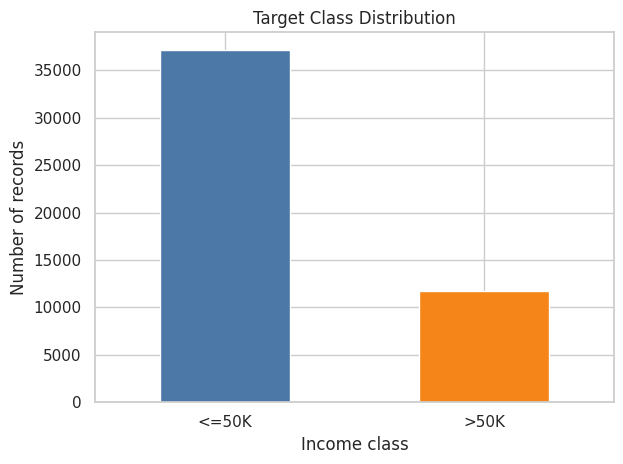

In [5]:

# Traget verification
TARGET = 'class'
if TARGET not in df.columns:
    raise KeyError(f"Expected target column '{TARGET}'. Available columns: {df.columns.tolist()}")

#Distribution Calculation
class_counts = df[TARGET].value_counts(dropna=False)
class_percent = (df[TARGET].value_counts(normalize=True, dropna=False) * 100).round(2)
class_distribution = pd.DataFrame({'count': class_counts, 'percent': class_percent})
display(class_distribution)
class_distribution.to_csv(OUTPUT_DIR / 'class_distribution.csv')

#Plotting
ax = class_counts.plot(kind='bar', color=['#4C78A8', '#F58518'], rot=0)
ax.set_title('Target Class Distribution')
ax.set_xlabel('Income class')
ax.set_ylabel('Number of records')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'class_distribution.png', dpi=180, bbox_inches='tight')
plt.show()

## Step 2: Data preprocessing

- Exact duplicate rows are removed before splitting.
- Missing numeric values are imputed with the training-set median.
- Missing categorical values are imputed with the training-set most-frequent category.
- Categorical features are one-hot encoded with unknown-category protection.
- Numeric features are standardized, which is especially important for Logistic Regression and KNN.
- An 80:20 split uses `stratify=y` to preserve class distribution and `random_state=42` for reproducibility.
- Every model is wrapped in a pipeline, so preprocessing is learned only from the training subset.

In [6]:
rows_before = len(df)

#Duplicate row removal
df = df.drop_duplicates().reset_index(drop=True)
rows_after = len(df)
print(f'Removed {rows_before - rows_after} duplicate rows; {rows_after} rows remain.')

# Robust Target Encoding
y_text = df[TARGET].astype('string').str.strip().str.replace('.', '', regex=False)
y = y_text.map({'<=50K': 0, '>50K': 1})
if y.isna().any():
    raise ValueError(f'Unexpected target labels: {sorted(y_text.dropna().unique().tolist())}')
y = y.astype(int)

# Feature splitting and Identification
X = df.drop(columns=[TARGET])

categorical_features = X.select_dtypes(include=['object', 'string', 'category']).columns.tolist()
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
# Scikit-Learn Data type compatibility
X[categorical_features] = X[categorical_features].astype(object).where(X[categorical_features].notna(), np.nan)

print('Numerical features:', numeric_features)
print('Categorical features:', categorical_features)

Removed 187 duplicate rows; 48655 rows remain.
Numerical features: ['age', 'fnlwgt', 'education-num', 'capitalgain', 'capitalloss', 'hoursperweek']
Categorical features: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


In [7]:
# Spliting the feature  to test with 20% and remaining 80% for training
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

split_distribution = pd.DataFrame({
    'Full dataset (%)': (y.value_counts(normalize=True).sort_index() * 100).round(2),
    'Training set (%)': (y_train.value_counts(normalize=True).sort_index() * 100).round(2),
    'Test set (%)': (y_test.value_counts(normalize=True).sort_index() * 100).round(2)
})
display(split_distribution)
print('Training shape:', X_train.shape)
print('Test shape:', X_test.shape)

,Full dataset (%),Training set (%),Test set (%)
class,,,
0,76.03,76.03,76.03
1,23.97,23.97,23.97


Training shape: (38924, 14)
Test shape: (9731, 14)


In [9]:
# Compatibility helper for old and new scikit-learn releases.
def make_one_hot_encoder():
    try:
        return OneHotEncoder(handle_unknown='ignore', sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown='ignore', sparse=False)

numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', make_one_hot_encoder())
])

preprocessor = ColumnTransformer(transformers=[
    ('numeric', numeric_pipeline, numeric_features),
    ('categorical', categorical_pipeline, categorical_features)
])

## Step 3: Classification models

The same training and test split is used for all five required models. The positive class is income `>50K`.

In [10]:
# Models:Logistic Regression,Decision Tree,K-Nearest Neighbors,Gaussian Naive Bayes and Random Forest
models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE),
    'Decision Tree': DecisionTreeClassifier(max_depth=12, min_samples_leaf=10, class_weight='balanced', random_state=RANDOM_STATE),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=11, weights='distance', n_jobs=-1),
    'Gaussian Naive Bayes': GaussianNB(),
    'Random Forest': RandomForestClassifier(
        n_estimators=250, min_samples_leaf=2, class_weight='balanced_subsample',
        random_state=RANDOM_STATE, n_jobs=-1
    )
}

pipelines = {
    name: Pipeline(steps=[('preprocessor', clone(preprocessor)), ('classifier', model)])
    for name, model in models.items()
}

In [11]:
#Initialization
results = []
fitted_models = {}
roc_data = {}
report_rows = []

# Training and Prediction
for name, pipeline in pipelines.items():
    print(f'Training {name}...')
    start = time.time()
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    if hasattr(pipeline, 'predict_proba'):
        y_score = pipeline.predict_proba(X_test)[:, 1]
    else:
        y_score = pipeline.decision_function(X_test)

#Metric Calculation
    metrics = {
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'AUC': roc_auc_score(y_test, y_score),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1 Score': f1_score(y_test, y_pred, zero_division=0),
        'MCC Score': matthews_corrcoef(y_test, y_pred),
        'Training Seconds': time.time() - start
    }
    results.append(metrics)
    fitted_models[name] = pipeline
    fpr, tpr, _ = roc_curve(y_test, y_score)
    roc_data[name] = (fpr, tpr, metrics['AUC'])

# Classification Reports & Confusion Matrices
    report = classification_report(y_test, y_pred, target_names=['<=50K', '>50K'], output_dict=True, zero_division=0)
    pd.DataFrame(report).transpose().to_csv(OUTPUT_DIR / f"classification_report_{name.lower().replace(' ', '_').replace('-', '')}.csv")

    cm = confusion_matrix(y_test, y_pred)
    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay(cm, display_labels=['<=50K', '>50K']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'Confusion Matrix: {name}')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"confusion_matrix_{name.lower().replace(' ', '_').replace('-', '')}.png", dpi=180, bbox_inches='tight')
    plt.close(fig)

    print(f"  completed in {metrics['Training Seconds']:.2f} seconds")

results_df = pd.DataFrame(results).sort_values('F1 Score', ascending=False).reset_index(drop=True)
results_df.to_csv(OUTPUT_DIR / 'model_evaluation_metrics.csv', index=False)
display(results_df.style.format({c: '{:.4f}' for c in results_df.columns if c != 'Model'}))

Training Logistic Regression...
  completed in 2.61 seconds
Training Decision Tree...
  completed in 1.45 seconds
Training K-Nearest Neighbors...
  completed in 20.22 seconds
Training Gaussian Naive Bayes...
  completed in 0.52 seconds
Training Random Forest...
  completed in 19.86 seconds


,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC Score,Training Seconds
0,Random Forest,0.8226,0.9053,0.5965,0.8041,0.6849,0.5774,19.8553
1,Logistic Regression,0.8071,0.9034,0.5664,0.8337,0.6745,0.5650,2.6098
2,Decision Tree,0.7959,0.8810,0.5493,0.8290,0.6607,0.5459,1.4513
3,K-Nearest Neighbors,0.8356,0.8744,0.6713,0.6155,0.6422,0.5366,20.2247
4,Gaussian Naive Bayes,0.6057,0.8243,0.3715,0.9314,0.5311,0.3787,0.5203


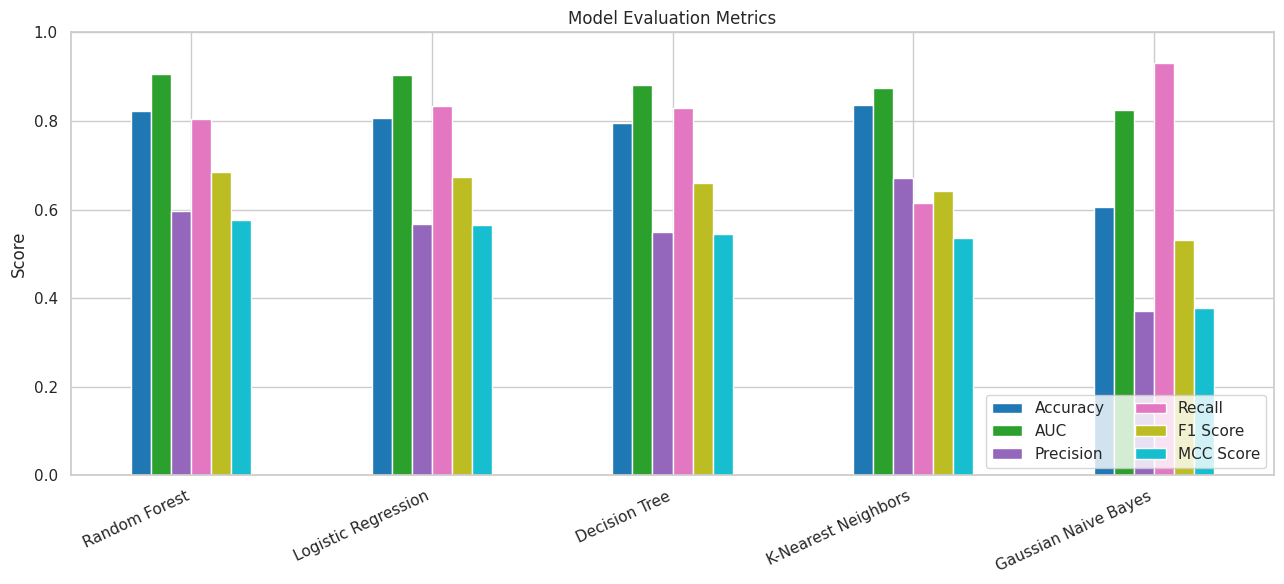

In [ ]:
# Comparison chart
metric_columns = ['Accuracy', 'AUC', 'Precision', 'Recall', 'F1 Score', 'MCC Score']
plot_df = results_df.set_index('Model')[metric_columns]
ax = plot_df.plot(kind='bar', figsize=(13, 6), ylim=(0, 1), colormap='tab10')
ax.set_title('Model Evaluation Metrics')
ax.set_ylabel('Score')
ax.set_xlabel('')
ax.legend(loc='lower right', ncol=2)
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'model_comparison.png', dpi=180, bbox_inches='tight')
plt.show()

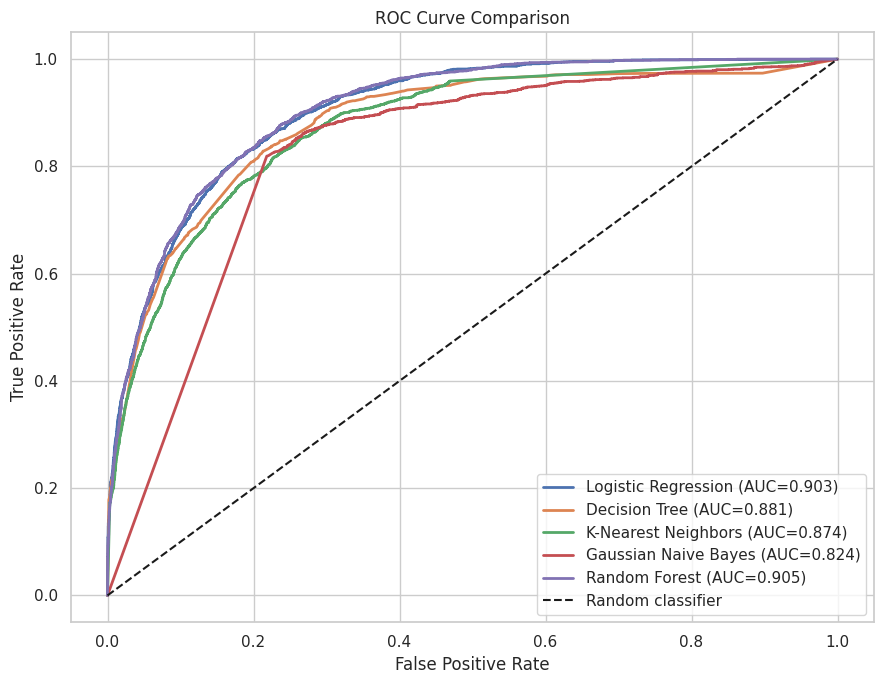

In [12]:
# ROC curves
plt.figure(figsize=(9, 7))
for name, (fpr, tpr, auc_value) in roc_data.items():
    plt.plot(fpr, tpr, linewidth=2, label=f'{name} (AUC={auc_value:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'roc_curve_comparison.png', dpi=180, bbox_inches='tight')
plt.show()

In [13]:
# Select the best model primarily by F1 score, with AUC as a tie-breaker.
best_row = results_df.sort_values(['F1 Score', 'AUC'], ascending=False).iloc[0]
best_model_name = best_row['Model']
best_model = fitted_models[best_model_name]
joblib.dump(best_model, OUTPUT_DIR / 'best_model_pipeline.joblib')

summary = {
    'best_model': best_model_name,
    'selection_rule': 'Highest F1 Score, then AUC as tie-breaker',
    'random_state': RANDOM_STATE,
    'train_rows': int(len(X_train)),
    'test_rows': int(len(X_test)),
    'numeric_features': numeric_features,
    'categorical_features': categorical_features,
    'output_directory': str(OUTPUT_DIR)
}
with open(OUTPUT_DIR / 'run_summary.json', 'w') as f:
    json.dump(summary, f, indent=2)

print('Best model:', best_model_name)
print(best_row.to_string())
print()
print('Saved outputs:')
for p in sorted(OUTPUT_DIR.iterdir()):
    print('-', p.name)

Best model: Random Forest
Model               Random Forest
Accuracy                 0.822629
AUC                      0.905313
Precision                0.596502
Recall                   0.804115
F1 Score                 0.684922
MCC Score                0.577444
Training Seconds        19.855289

Saved outputs:
- best_model_pipeline.joblib
- class_distribution.csv
- class_distribution.png
- classification_report_decision_tree.csv
- classification_report_gaussian_naive_bayes.csv
- classification_report_knearest_neighbors.csv
- classification_report_logistic_regression.csv
- classification_report_random_forest.csv
- confusion_matrix_decision_tree.png
- confusion_matrix_gaussian_naive_bayes.png
- confusion_matrix_knearest_neighbors.png
- confusion_matrix_logistic_regression.png
- confusion_matrix_random_forest.png
- data_quality_summary.csv
- model_comparison.png
- model_evaluation_metrics.csv
- roc_curve_comparison.png
- run_summary.json


## Interpretation guide

- **Accuracy**: overall fraction of correct predictions, but it can be optimistic when classes are imbalanced.
- **AUC**: ability to rank positive cases above negative cases across all thresholds.
- **Precision**: among records predicted as `>50K`, the fraction truly above 50K.
- **Recall**: among records truly above 50K, the fraction found by the model.
- **F1 Score**: harmonic mean of precision and recall; used here as the primary selection metric.
- **MCC**: balanced correlation-style score using all four confusion-matrix cells; useful for imbalanced classification.

The final numerical conclusions are generated from the supplied CSV when all cells are run. The model with the highest F1 score is saved as `best_model_pipeline.joblib`, and all tabular/graphical outputs are stored in the requested Google Drive output directory.